# Script de communication STM32 & Python

Elaboration d'un algorythme de lecture série des données de la carte

In [29]:
# ========================
# Import des modules
# ========================

import serial
import time
import math
import threading
import serial.tools.list_ports
import matplotlib.pyplot as plt
import numpy

In [30]:
#Global variables

measured_tests = []

In [31]:
# ========================================
# Lancement de la communication pySerial
# ========================================

#Lists all ports
ports = serial.tools.list_ports.comports()

open_ports = ""
descr = ""

# Script de recherche de port STM32
for port, desc, hwid in sorted(ports):
        ##print("{}: {} [{}]".format(port, desc, hwid))
        ##print("{}".format(port))
        descr = "{}".format(desc)
        if (descr == "STM32 STLink - ST-Link VCP Ctrl"):
            open_ports = "{}".format(port)

print("Open ports : ", open_ports)

## Réglages spécifiques du canal de communication
data_serial = serial.Serial(
    port=open_ports,
    baudrate=921600,#576000,#115200,
    parity=serial.PARITY_NONE,
    stopbits=serial.STOPBITS_ONE,
    bytesize=serial.EIGHTBITS

)
data_serial.writeTimeout = 0 
data_serial.isOpen()
print(data_serial)

Open ports :  /dev/ttyACM1
Serial<id=0x7f72a8f9e3e0, open=True>(port='/dev/ttyACM1', baudrate=921600, bytesize=8, parity='N', stopbits=1, timeout=None, xonxoff=False, rtscts=False, dsrdtr=False)


In [19]:
# ==============================
# Fermeture de la communication
# ==============================

data_serial.close()
data_serial.isOpen()

False

In [32]:
# Vérification de l'ouverture du port
data_serial.isOpen()

True

## TX / Emission des données

In [33]:
# =================================
# IDs TX/RX
# =================================

ID_RX_START = b'0x01'
ID_RX_STOP = b'0x02'
ID_RX_PWM_START = b'0x03'
ID_RX_PWM_STOP = b'0x04'
ID_RX_DUTY_SET = b'0x05'
ID_RX_DIR = b'0x06'
ID_RX_VOLTAGE_SET = b'0x07'
ID_RX_SET_MAG = b'0x08'
ID_RX_SET_COMMAND = b'0x09'

ID_RX_ACK = b'0xFF'
ID_RX_CALIBRATE = b'0xFE'
ID_RX_CALIB_ZEROG = b'0xFA'
ID_RX_CALIB_MINUSG = b'0xFB'
ID_RX_CALIB_PLUSG = b'0xFC'

ID_RX_SEND_KP = b'0x0A'
ID_RX_SET_KP = b'0x0B'
ID_RX_SEND_KI = b'0x0C'
ID_RX_SET_KI = b'0x0D'
ID_RX_SEND_KD = b'0x0E'
ID_RX_SET_KD = b'0x0F'

# =================================
# trames
# =================================

def define_trame(msg_id, value, max_size):
    #init
    trame = b''
    byte_length = b''
    
    byte_length = bytes(str(value),'utf-8')
    float_byte_size = len(byte_length)
    index_max_byte = max_size-len(msg_id)-2
    print("index_max_byte :",index_max_byte, " max_size :", max_size)
    trame = msg_id+byte_length[0:index_max_byte]+b';'
    
    #zero filler
    zero_filler = b'0'*(max_size - len(trame)-1)
    trame+= zero_filler
    #EOF Character to end the line, counts as 1 bytes
    trame = trame + bytes('\n', 'utf-8') + bytes('\n', 'utf-8')
    return trame

# =================================
# fonctions d'envoi
# =================================

MSG_MAX_SIZE = 16

def uart_send_start():
    data_serial.write(define_trame(ID_RX_START, 1, MSG_MAX_SIZE+1))
    
def uart_send_stop():
    data_serial.write(define_trame(ID_RX_STOP, 1, MSG_MAX_SIZE+1))
    
def uart_send_pwmStart():
    data_serial.write(define_trame(ID_RX_PWM_START, 1, MSG_MAX_SIZE+1))
    
def uart_send_pwmStop():
    data_serial.write(define_trame(ID_RX_PWM_STOP, 1, MSG_MAX_SIZE+1))
    
def uart_send_dutyValue(duty_value):
    data_serial.write(define_trame(ID_RX_DUTY_SET, duty_value, MSG_MAX_SIZE+1))
    
def uart_send_command(command):
    data_serial.write(define_trame(ID_RX_SET_COMMAND, command, MSG_MAX_SIZE+1))
    
def uart_send_direction(dir_value):
    data_serial.write(define_trame(ID_RX_DIR, dir_value, MSG_MAX_SIZE+1))
    
def uart_send_voltageValue(voltage_value):
    print("b'' sent : ",data_serial.write(define_trame(ID_RX_VOLTAGE_SET, voltage_value, MSG_MAX_SIZE+1)))
    
def uart_send_kpAsk(kp_value):
    data_serial.write(define_trame(ID_RX_SET_KP, kp_value, MSG_MAX_SIZE+1))
    
def uart_send_kpValue():
    data_serial.write(define_trame(ID_RX_SEND_KP, 1, MSG_MAX_SIZE+1))
    
def uart_send_kiAsk(ki_value):
    data_serial.write(define_trame(ID_RX_SET_KI, ki_value, MSG_MAX_SIZE+1))
    
def uart_send_kiValue():
    data_serial.write(define_trame(ID_RX_SEND_KI, 1, MSG_MAX_SIZE+1))
    
def uart_send_kdAsk(kd_value):
    data_serial.write(define_trame(ID_RX_SET_KD, kd_value, MSG_MAX_SIZE+1))
    
def uart_send_kdValue():
    data_serial.write(define_trame(ID_RX_SEND_KD, 1, MSG_MAX_SIZE+1))
    
def uart_send_acknowledge():
    data_serial.write(define_trame(ID_RX_ACK, 1, MSG_MAX_SIZE+1))
    
def uart_send_calibrate():
    data_serial.write(define_trame(ID_RX_CALIBRATE, 1, MSG_MAX_SIZE+1))
    
def uart_send_calibzeroG():
    data_serial.write(define_trame(ID_RX_CALIB_ZEROG, 1, MSG_MAX_SIZE+1))
    
def uart_send_calibminusG():
    data_serial.write(define_trame(ID_RX_CALIB_MINUSG, 1, MSG_MAX_SIZE+1))
    
def uart_send_calibplusG():
    data_serial.write(define_trame(ID_RX_CALIB_PLUSG, 1, MSG_MAX_SIZE+1))
    
def uart_send_mag(state_int):
    data_serial.write(define_trame(ID_RX_SET_MAG, state_int, MSG_MAX_SIZE+1))

### Tests des fonctions d'émission

In [7]:
uart_send_mag(1)

index_max_byte : 10  max_size : 16


In [9]:
uart_send_mag(0)

index_max_byte : 10  max_size : 16


In [9]:
uart_send_start()

index_max_byte : 10  max_size : 16


In [10]:
uart_send_stop()

index_max_byte : 10  max_size : 16


In [8]:
uart_send_dutyValue(100.0)

index_max_byte : 11  max_size : 17


In [9]:
uart_send_dutyValue(0.0)

index_max_byte : 11  max_size : 17


## Calibration accelero

In [12]:
uart_send_calibzeroG()

index_max_byte : 10  max_size : 16


In [13]:
uart_send_calibminusG()

index_max_byte : 10  max_size : 16


In [14]:
uart_send_calibplusG()

index_max_byte : 10  max_size : 16


In [15]:
uart_send_calibrate()

index_max_byte : 10  max_size : 16


## RX / Lecture & Traitement des données

In [34]:
# =================================
# Read
# =================================
def read_data(nline):
    data_serial.reset_input_buffer()
    data_serial.reset_output_buffer()
    
    it = 0
    print("start reading")
    ##error while reading previous values
    ##kinda flush
    data_table = []
    while (it != nline+50):
        # Read data out of the buffer until a carraige return / new line is found
        data = (data_serial.readline()).decode()
        data = data.split(";")
        #print(data)
        
        data_table.append(data)
        it += 1;
        #print(it)
    print("out")
    data_table = data_table[50:nline+1]
    return data_table

# =================================
# Processing
# =================================
def compute_data_table(dt):
    ndt = []
    tables = []
    
    for data_line in dt:
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            data_line[0] = data_line[0].lstrip('\r') #supprime le \r caractere
            
            for i in range(0, len(data_line)):
                if ((i%2) == 1):
                    data_line[i] = float(data_line[i])
        ndt.append(data_line)
    return ndt

# =================================
# Slicing
# =================================
def time_getTable(dt):
    ndt = []
    for data_line in dt:
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            for k in range(len(data_line)):
                if (type(data_line[k]) == type("0x0")): # "0x01" in data_line[k] only for string
                    if ("0x01" in data_line[k]):
                        ndt.append((data_line[k+1])/1000)
    
    init_time = ndt[0]
    for j in range(len(ndt)):
        ndt[j] = round(ndt[j] - init_time, 3) #3 digit after . as it is divised by 10e3
    
    return ndt

def pwm_getTable(dt):
    ndt = []
    for data_line in dt:
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            ##print(data_line)
            for k in range(len(data_line)):
                if (type(data_line[k]) == type("0x0")):
                    if ("0x11" in data_line[k]):
                        ndt.append(data_line[k+1])
                    
    return ndt

def adc_getTable(dt):
    ndt = []
    for data_line in dt:
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            for k in range(len(data_line)):
                if (type(data_line[k]) == type("0x0")):
                    if ("0x09" in data_line[k]):
                        ndt.append(data_line[k+1])
                    
    return ndt

def accel_getTable(dt):
    ndt = []
    for data_line in dt:
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            for k in range(len(data_line)):
                if (type(data_line[k]) == type("0x0")):
                    if ("0x10" in data_line[k]):
                        ndt.append(data_line[k+1])
                    
    return ndt

def speed_getTable(dt):
    ndt = []
    for data_line in dt:
        #print("DATA LINE :", data_line, len(data_line))
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            for k in range(len(data_line)):
                if (type(data_line[k]) == type("0x0")):
                    if ("0x12" in data_line[k]):
                        ndt.append(data_line[k+1])
                    
    return ndt

def all_getTable(dt):
    ndt = []
    
    for data_line in dt:
        ndtline = [0]*5
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            for k in range(len(data_line)):
                if (type(data_line[k]) == type("0x0")):
                    if ("0x01" in data_line[k]):
                        ndtline[0] = ((data_line[k+1])/1000)
                    if ("0x09" in data_line[k]):
                        ndtline[1] = (data_line[k+1])
                    if ("0x10" in data_line[k]):
                        ndtline[2] = (data_line[k+1])
                    if ("0x11" in data_line[k]):
                        ndtline[3] = (data_line[k+1])
                    if ("0x12" in data_line[k]):
                        ndtline[4] = (data_line[k+1])
                        
        ndt.append(ndtline)
        
    init_time = ndt[0][0]
    for j in range(len(ndt)):
        ndt[j][0] = round(ndt[j][0] - init_time, 3) #3 digit after . as it is divised by 10e3
    
    return ndt

## Tests de lecture

In [42]:
# ========================
# Lecture pour 5s
# ========================

t0 = time.time()
data_test = read_data(5000)
t1 = time.time()
print(t1-t0)

start reading
out
5.009745836257935


In [43]:
# ==================================
# Affichage des données brut reçues
# ==================================

print(data_test)

[['\r\x000x01', '86365', '0x09', '1.661', '0x10', '-0.101', '0x11', '0', '0x12', '-9375.00', '\n'], ['\r\x000x01', '86366', '0x09', '1.660', '0x10', '-0.099', '0x11', '0', '0x12', '-9375.00', '\n'], ['\r\x000x01', '86367', '0x09', '1.660', '0x10', '-0.099', '0x11', '0', '0x12', '-9375.00', '\n'], ['\r\x000x01', '86368', '0x09', '1.660', '0x10', '-0.099', '0x11', '0', '0x12', '-9375.00', '\n'], ['\r\x000x01', '86369', '0x09', '1.660', '0x10', '-0.099', '0x11', '0', '0x12', '-9375.00', '\n'], ['\r\x000x01', '86370', '0x09', '1.660', '0x10', '-0.099', '0x11', '0', '0x12', '-9375.00', '\n'], ['\r\x000x01', '86371', '0x09', '1.660', '0x10', '-0.099', '0x11', '0', '0x12', '-9375.00', '\n'], ['\r\x000x01', '86372', '0x09', '1.660', '0x10', '-0.099', '0x11', '0', '0x12', '-9375.00', '\n'], ['\r\x000x01', '86373', '0x09', '1.660', '0x10', '-0.099', '0x11', '0', '0x12', '-9375.00', '\n'], ['\r\x000x01', '86374', '0x09', '1.660', '0x10', '-0.099', '0x11', '0', '0x12', '-9375.00', '\n'], ['\r\x000

In [44]:
# ===========================================
# Affichage des données reçues pré-traitées
# ===========================================

computed_data = (compute_data_table(data_test))
print(computed_data)

[['\x000x01', 86365.0, '0x09', 1.661, '0x10', -0.101, '0x11', 0.0, '0x12', -9375.0, '\n'], ['\x000x01', 86366.0, '0x09', 1.66, '0x10', -0.099, '0x11', 0.0, '0x12', -9375.0, '\n'], ['\x000x01', 86367.0, '0x09', 1.66, '0x10', -0.099, '0x11', 0.0, '0x12', -9375.0, '\n'], ['\x000x01', 86368.0, '0x09', 1.66, '0x10', -0.099, '0x11', 0.0, '0x12', -9375.0, '\n'], ['\x000x01', 86369.0, '0x09', 1.66, '0x10', -0.099, '0x11', 0.0, '0x12', -9375.0, '\n'], ['\x000x01', 86370.0, '0x09', 1.66, '0x10', -0.099, '0x11', 0.0, '0x12', -9375.0, '\n'], ['\x000x01', 86371.0, '0x09', 1.66, '0x10', -0.099, '0x11', 0.0, '0x12', -9375.0, '\n'], ['\x000x01', 86372.0, '0x09', 1.66, '0x10', -0.099, '0x11', 0.0, '0x12', -9375.0, '\n'], ['\x000x01', 86373.0, '0x09', 1.66, '0x10', -0.099, '0x11', 0.0, '0x12', -9375.0, '\n'], ['\x000x01', 86374.0, '0x09', 1.66, '0x10', -0.099, '0x11', 0.0, '0x12', -9375.0, '\n'], ['\x000x01', 86375.0, '0x09', 1.66, '0x10', -0.099, '0x11', 0.0, '0x12', -9375.0, '\n'], ['\x000x01', 86376.

In [45]:
# ==================================
# Affichage des données traitées
# ==================================
current_measure = all_getTable(computed_data)
print(current_measure)

[[0.0, 1.661, -0.101, 0.0, -9375.0], [0.001, 1.66, -0.099, 0.0, -9375.0], [0.002, 1.66, -0.099, 0.0, -9375.0], [0.003, 1.66, -0.099, 0.0, -9375.0], [0.004, 1.66, -0.099, 0.0, -9375.0], [0.005, 1.66, -0.099, 0.0, -9375.0], [0.006, 1.66, -0.099, 0.0, -9375.0], [0.007, 1.66, -0.099, 0.0, -9375.0], [0.008, 1.66, -0.099, 0.0, -9375.0], [0.009, 1.66, -0.099, 0.0, -9375.0], [0.01, 1.66, -0.099, 0.0, -9375.0], [0.011, 1.658, -0.093, 0.0, -9375.0], [0.012, 1.657, -0.088, 0.0, -9375.0], [0.013, 1.657, -0.088, 0.0, -9375.0], [0.014, 1.658, -0.091, 0.0, -9375.0], [0.015, 1.657, -0.088, 0.0, -9375.0], [0.016, 1.655, -0.083, 0.0, -9375.0], [0.017, 1.654, -0.08, 0.0, -9375.0], [0.018, 1.655, -0.083, 0.0, -9375.0], [0.019, 1.654, -0.077, 0.0, -9375.0], [0.02, 1.654, -0.077, 0.0, -9375.0], [0.021, 1.653, -0.075, 0.0, -9375.0], [0.022, 1.651, -0.07, 0.0, -9375.0], [0.023, 1.652, -0.072, 0.0, -9375.0], [0.024, 1.65, -0.067, 0.0, -9375.0], [0.025, 1.651, -0.07, 0.0, -9375.0], [0.026, 1.651, -0.07, 0.0, -9

## Mesures vibratoires

In [100]:
# =================================
# Mesure des vibrations en relâche
# =================================

time_table = []
speed_table = []
adc_table = []
accel_table = []
pwm_table = []

def release_accel(te_ms, period_ms):
    print("Thread %s: starting")
    time.sleep((te_ms/period_ms)*0.1)
    uart_send_mag(0)
    print("Thread %s: finishing")

def measure_release(te_ms, period_ms):
    #reboot input buffer
    global time_table, speed_table, adc_table, accel_table, pwm_table
    initial_measure = []
    core_measure = []
    thread_release = threading.Thread(target=release_accel, args=(te_ms,period_ms), daemon = True)
    # =================================
    # Mesures
    # =================================
    print("=== Lancement des mesures ===")
    print("Temps : "+str(te_ms)+"ms")
    print("--> Relaĉhe de l'aimant")
    thread_release.start()
    core_measure = read_data(int((te_ms/period_ms)))
    
    print("--> Fin de la mesure")
    #thread_release.stop()
    # =================================
    # Traitements
    # =================================
    print("=== Traitement des mesures ===")
    print("--> Traitement principal")
    computed_data = (compute_data_table(core_measure))
    print("--> Découpage des tables")
    computed_data = (all_getTable(computed_data))
    return computed_data
    print("--> Retour")
    
# =================================
# Constantes
# =================================

max_motor_speed = 166.667 #tr/s

# ======================================
# Mesure des vibrations en régime forcé
# ======================================

time_table = []
speed_table = []
adc_table = []
accel_table = []
pwm_table = []

def freq2duty(freq):
    duty = int(round(freq/max_motor_speed, 4)*1000)
    # duty is an integer between 0 and 100 (0.x precision when %)
    return duty


def tx_command(length_ms, max_freq, freq_step, min_freq):
    print("Thread %s: starting")
    #nb of points
    max_points = int( (max_freq-min_freq)/freq_step ) + 1 #+1 for step @ 0 Hz
    #initial period of null freq
    uart_send_command(freq2duty(0.0))
    for step in range(0, max_points):
        time.sleep(length_ms/1000)
        freq = max_freq - step*freq_step
        uart_send_command(freq2duty(freq))
        
    #final period of null freq to finish the measure
    uart_send_command(freq2duty(0.0))
    print("Thread %s: finishing")

        
'''
# Parametres

te_ms : Période d'échantillonage
length_ms : Longueur de mesure PAR fréquence
max_freq : frequence stimulée max
freq_step : pas de frequence
min_freq : frequence stimulée min

# Description

La fonction initie une série de mesures bloquantes.
La commande part de la fréquence max vers la fréquence min avec un pas freq_step
Le post-traitement est directement fait par la fonction
'''        

def measure_forced_vibrations(te_ms, length_ms, max_freq, freq_step, min_freq):
    #reboot input buffer
    global time_table, speed_table, adc_table, accel_table, pwm_table
    core_measure = []
    
    measuring_time = (int( (max_freq-min_freq)/freq_step ) + 1)*(length_ms/1000)
    reading_points = int(measuring_time*1000/te_ms)
    
    thread_command = threading.Thread(target=tx_command, 
                                      args=(length_ms, max_freq, freq_step, min_freq), 
                                      daemon = True)
    # =================================
    # Mesures
    # =================================
    print("=== Lancement des mesures ===")
    print("Temps total: "+str(measuring_time)+"s"+" | "+str(measuring_time/60)+ "min")
    print("--> Début de la mesure")
    thread_command.start()
    core_measure = read_data(reading_points)
    
    print("--> Fin de la mesure")
    # =================================
    # Traitements
    # =================================
    print("=== Traitement des mesures ===")
    print("--> Traitement principal")
    computed_data = (compute_data_table(core_measure))
    print("--> Découpage des tables")
    return (all_getTable(computed_data))
    print("--> Retour")

In [13]:
current_measure = measure_forced_vibrations(te_ms=1, length_ms=30000, max_freq=10, freq_step=0.5, min_freq=0)

=== Lancement des mesures ===
Temps total: 630.0s | 10.5min
--> Début de la mesure
Thread %s: starting


Exception in thread Thread-10 (tx_command):
Traceback (most recent call last):
  File "/usr/lib/python3.10/threading.py", line 1016, in _bootstrap_inner
    self.run()
  File "/usr/lib/python3.10/threading.py", line 953, in run
    self._target(*self._args, **self._kwargs)
  File "/tmp/ipykernel_55383/3969310603.py", line 32, in tx_command


NameError: name 'read_data' is not defined

  File "/tmp/ipykernel_55383/4151029496.py", line 72, in uart_send_command
NameError: name 'data_serial' is not defined


## Affichage des données

In [40]:
# ==========================
# utils
# ==========================

def extract_table(dt, index):
    ndt = [0]*len(dt)
    for i in range(len(dt)):
        ndt[i] = dt[i][index]
    return ndt

# ==========================
# Plot un set de data
# ==========================

def plot_speed(dt):
    time_table = extract_table(dt, 0)
    pwm_table = extract_table(dt, 3)
    speed_table = extract_table(dt, 4)
    
    for i in range(len(pwm_table)):
        pwm_table[i] = 280*(pwm_table[i]/1000)
    max_len = min(len(time_table), min(len(pwm_table),len(speed_table)))
    plt.plot(time_table[0:max_len],pwm_table[0:max_len], label = "Commande")
    plt.plot(time_table[0:max_len], speed_table[0:max_len], label = "Vitesse")
    plt.xlabel("Temps (s)")
    plt.ylim([-100, 500])
    plt.ylabel("Vitesse (rpm)")
    plt.title(str(len(time_table))+" mesures d'ADC en série")
    plt.legend()
    
def plot_adc(dt):
    time_table = extract_table(dt, 0)
    print(len(time_table))
    accel_table = extract_table(dt, 1)
    print(len(accel_table))
    max_len = min(len(time_table), len(accel_table))
    plt.step(time_table[0:max_len],accel_table[0:max_len], label = "Mesure ADC")
    plt.xlabel("Temps (s)")
    plt.ylim([0.4, 2.7])
    plt.ylabel("Amplitude (V)")
    plt.title(str(len(time_table))+" mesures d'ADC")
    plt.legend()
    
def plot_accel(dt):
    time_table = extract_table(dt, 0)
    print(len(time_table))
    accel_table = extract_table(dt, 2)
    print(len(accel_table))
    max_len = min(len(time_table), len(accel_table))
    plt.step(time_table[0:max_len],accel_table[0:max_len], label = "Mesure d'accelero")
    plt.xlabel("Temps (s)")
    plt.ylim([-3.2, 3.2])
    plt.ylabel("Amplitude (G)")
    plt.title(str(len(time_table))+" mesures d'accelero")
    plt.legend()

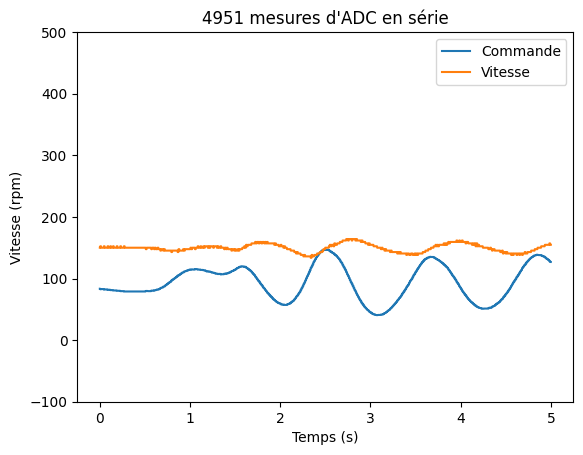

In [27]:
plot_speed(current_measure)

4951
4951


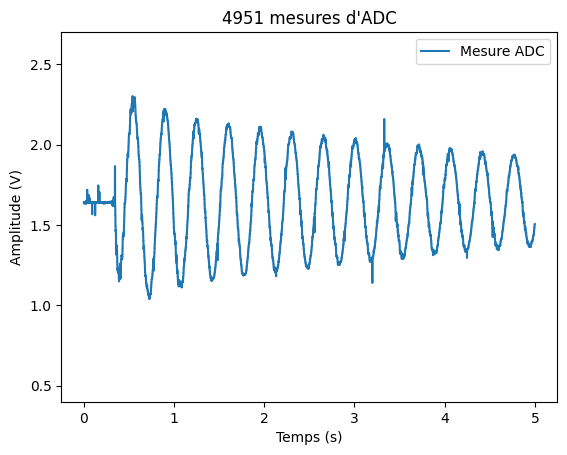

In [12]:
plot_adc(current_measure)

4951
4951


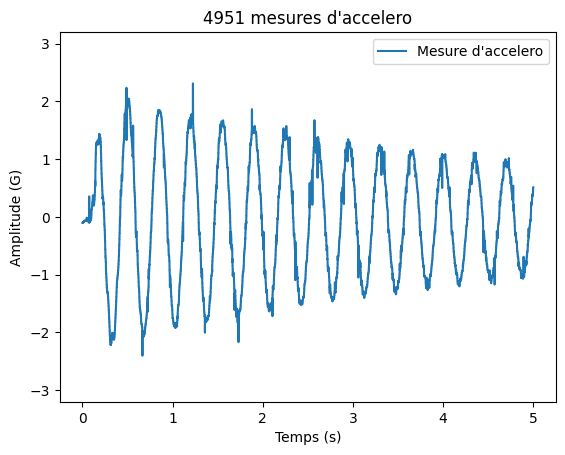

In [46]:
plot_accel(current_measure)

## Export CSV

In [41]:
import csv

with open('Measurements/P1FRF.csv', mode='w') as P1FRF:
    P1FRF_writer = csv.writer(P1FRF, delimiter=';', quotechar='"', quoting=csv.QUOTE_MINIMAL)

    for i in range(len(current_measure)):
        line = [current_measure[i][0], current_measure[i][2]]
        P1FRF_writer.writerow(line)
    
    print("out")


out


In [46]:
P1FRF_data = []
with open('Measurements/P3FRF.csv') as csv_file:
    csv_reader = csv.reader(csv_file, delimiter=';')
    line_count = 0
    for row in csv_reader:
        P1FRF_data.append([float(row[0]), float(row[1])])
    print("out")
    
print(P1FRF_data)

out
[[0.0, -0.048], [0.001, -0.054], [0.002, -0.059], [0.003, -0.056], [0.005, -0.051], [0.006, -0.051], [0.007, -0.056], [0.008, -0.054], [0.009, -0.048], [0.01, -0.051], [0.011, -0.048], [0.012, -0.048], [0.013, -0.067], [0.014, -0.046], [0.015, -0.054], [0.016, -0.056], [0.017, -0.054], [0.018, -0.051], [0.019, -0.054], [0.02, -0.048], [0.021, -0.043], [0.022, -0.059], [0.023, -0.054], [0.024, -0.051], [0.025, -0.051], [0.026, -0.054], [0.027, -0.054], [0.028, -0.043], [0.029, -0.051], [0.03, -0.043], [0.031, -0.062], [0.032, -0.048], [0.033, -0.048], [0.034, -0.051], [0.035, -0.054], [0.036, -0.048], [0.037, -0.048], [0.038, -0.046], [0.039, -0.048], [0.04, -0.054], [0.041, -0.051], [0.042, -0.048], [0.043, -0.048], [0.044, -0.048], [0.045, -0.043], [0.046, -0.046], [0.047, -0.056], [0.048, -0.054], [0.049, -0.051], [0.05, -0.043], [0.051, -0.046], [0.052, -0.077], [0.053, -0.048], [0.054, -0.048], [0.055, -0.051], [0.056, -0.048], [0.057, -0.048], [0.058, -0.051], [0.059, -0.051],

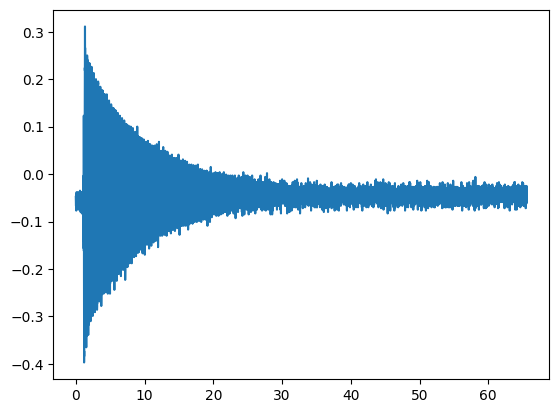

In [47]:
plt.plot(extract_table(P1FRF_data, 0), extract_table(P1FRF_data, 1))